<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo deste exercício é explorar a IA ML Cluster - IA não supervisionada. Mini Projeto em pares, escolher dados no Kaggle (dados diferentes por equipe) e experimentar/explorar um modelo de cluster como K-Means, AffinityPropagation, etc... publicar o notebook EDA no GitHub e subir o link do repo no MS Teams na atividade.

**Fontes**


*   https://www.kaggle.com/
*   https://scikit-learn.org/stable/modules/clustering.html




## 1. O que é Aprendizado Não Supervisionado e Clusterização?
No **Aprendizado Não Supervisionado**, os dados fornecidos ao algoritmo não possuem rótulos (labels). O objetivo da IA é encontrar estruturas ocultas, padrões ou agrupamentos naturais nos dados por conta própria.

A **Clusterização (Agrupamento)** é a técnica mais comum dessa categoria. Ela divide os dados em grupos (clusters) de forma que pontos no mesmo grupo sejam o mais semelhantes possível entre si, e o mais diferentes possível dos pontos de outros grupos.

Neste projeto, utilizaremos o **K-Means**, um algoritmo que particiona os dados em $K$ clusters distintos, minimizando a variância dentro de cada grupo.

In [4]:
!pip install kagglehub -q #Instalação necessária para obter o DataDrame do Kaggle
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Análise Exploratória de Dados (EDA)
Antes de aplicar qualquer modelo, precisamos entender nossos dados. A EDA nos ajuda a identificar distribuições, valores ausentes e correlações.

*Nota: Para garantir a reprodutibilidade do projeto, o dataset `Mall_Customers.csv` é importado diretamente via API do Kaggle (`kagglehub`), eliminando a necessidade de download e upload manual de arquivos na sessão do Colab.*

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



--- Informações do Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


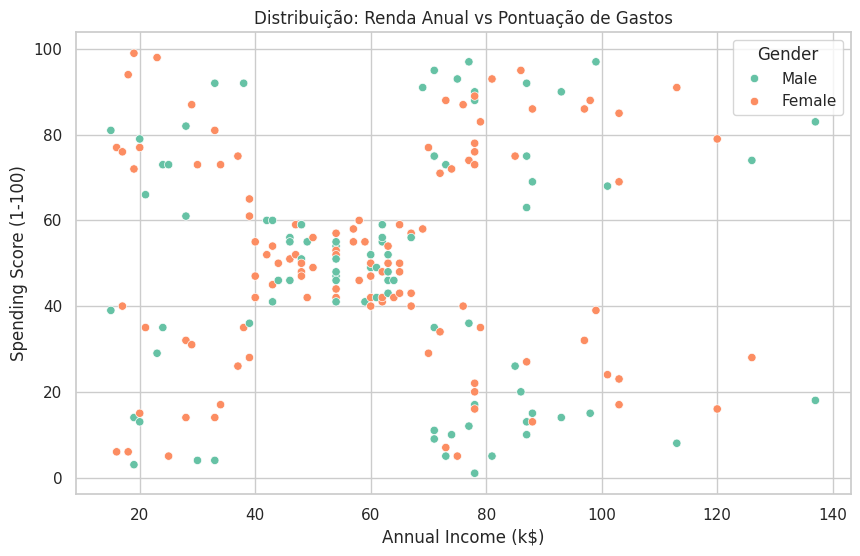

In [8]:
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
caminho_csv = f"{path}/Mall_Customers.csv"

df = pd.read_csv(caminho_csv)
display(df.head())

print("\n--- Informações do Dataset ---")
df.info()

display(df.describe())

plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Gender', palette='Set2')
plt.title('Distribuição: Renda Anual vs Pontuação de Gastos')
plt.show()

## 3. Preparando os Dados e Descobrindo o 'K' ideal
Para o K-Means, precisamos definir previamente o número de clusters ($K$). Como não sabemos qual é o número ideal, utilizamos o **Método do Cotovelo (Elbow Method)**.

Ele calcula a Soma dos Quadrados Intra-Cluster (WCSS - *Within-Cluster Sum of Square*). O ponto onde a queda do WCSS começa a desacelerar (formando um "cotovelo") é geralmente o número ideal de clusters.

Vamos utilizar apenas as colunas `Annual Income` e `Spending Score` para facilitar a visualização em 2D.

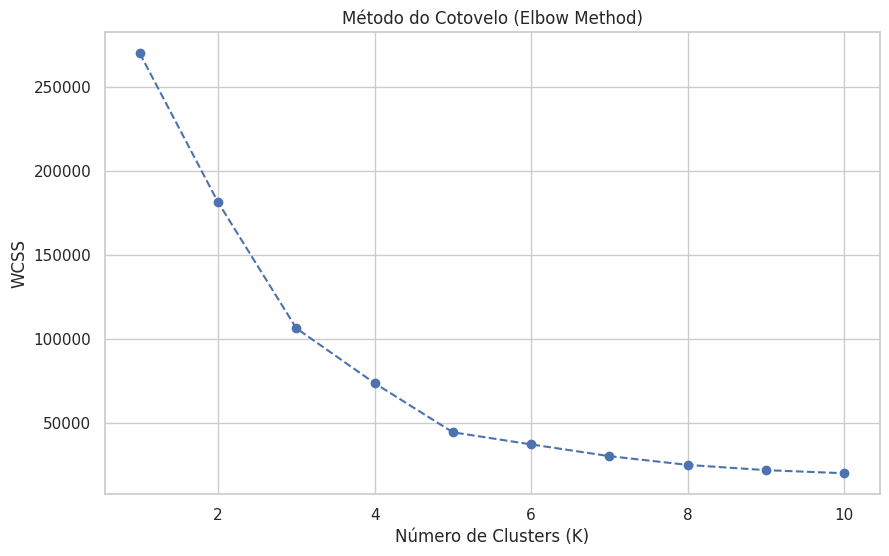

In [10]:
X = df.iloc[:, [3, 4]].values

wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Método do Cotovelo (Elbow Method)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('WCSS')
plt.show()

## 4. Aplicação do Modelo K-Means
Analisando o gráfico acima, percebemos que o "cotovelo" se forma no $K=5$. Portanto, vamos treinar nosso modelo K-Means dividindo nossos clientes em 5 grupos.

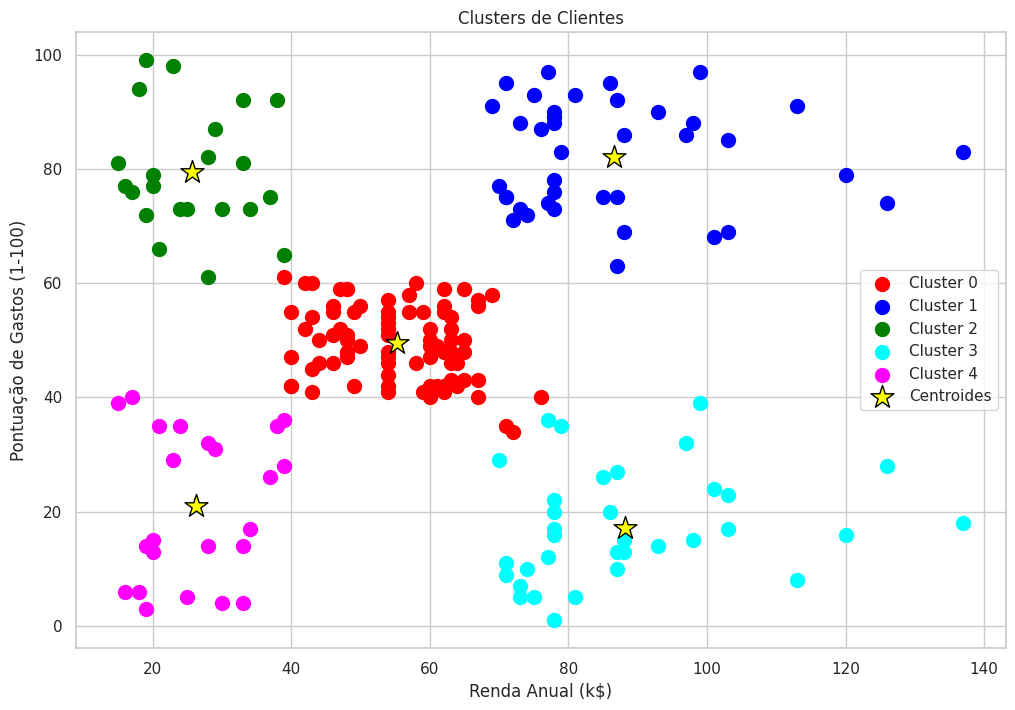

In [12]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)

df['Cluster'] = y_kmeans

# Visualizando os Clusters
plt.figure(figsize=(12,8))

cores = ['red', 'blue', 'green', 'cyan', 'magenta']
for i in range(5):
    plt.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1], s=100, c=cores[i], label=f'Cluster {i}')

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow', label='Centroides', edgecolor='black', marker='*')

plt.title('Clusters de Clientes')
plt.xlabel('Renda Anual (k$)')
plt.ylabel('Pontuação de Gastos (1-100)')
plt.legend()
plt.show()

## 5. Conclusões da Análise (EDA + Clusterização)
Com base na clusterização, conseguimos identificar 5 perfis distintos de clientes no shopping:
1. **Alta Renda / Alto Gasto (Cluster verde/azul):** Clientes alvo. Podem receber campanhas de marketing de produtos premium.
2. **Alta Renda / Baixo Gasto:** Clientes cuidadosos. Podem ser atraídos por promoções de custo-benefício.
3. **Baixa Renda / Alto Gasto:** Clientes impulsivos.
4. **Baixa Renda / Baixo Gasto:** Clientes conservadores.
5. **Renda Média / Gasto Médio:** O público geral (massa) do shopping.

Este tipo de IA não supervisionada nos permite gerar *insights* de negócios valiosos a partir de dados brutos, agrupando elementos com características semelhantes sem a necessidade de intervenção humana prévia.